# Reglas de asociación en drafts de League of Legends

**Minería de Datos · Proyecto**
Edgar Ivan Galvez Ortega · 180235-A


**Pregunta de minería:** ¿qué combinaciones de campeones aparecen juntas más de lo que se esperaría por pura
popularidad, y cuáles de ellas se asocian con ganar?

**Datos:** partidas clasificatorias (SoloQ) de la región LAN en rangos Platino, Esmeralda y Diamante, parches
16.19 a 16.21, descargadas de la API oficial de Riot Games para el proyecto *LoL Draft Predictor*.

**Contenido**

1. Carga y limpieza de los datos
2. Exploración
3. De partidas a transacciones
4. Apriori contra FP-Growth
5. Análisis A: campeones que se eligen juntos
6. Análisis B: campeón + rol
7. Análisis C: combinaciones asociadas con la victoria
8. Análisis D: asociaciones contra el equipo rival
9. Comparación por rango
10. Visualizaciones
11. Mini recomendador basado en reglas
12. Conclusiones, limitaciones y pendientes

In [1]:
import itertools
import json
import time
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
import seaborn as sns
from mlxtend.frequent_patterns import apriori, association_rules, fpgrowth
from mlxtend.preprocessing import TransactionEncoder

pd.set_option("display.max_colwidth", 60)
pd.set_option("display.float_format", "{:.4f}".format)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

## 1. Carga y limpieza de los datos

Cada línea de `datos/todas.jsonl` es una partida con dos equipos (`azul` y `rojo`). De cada equipo se conoce
si ganó, sus 5 campeones con rol y sus baneos. Se descartan partidas repetidas y las que no tienen los 5
campeones en ambos equipos. Cada partida produce **dos transacciones**, una por equipo.

In [2]:
RUTA = Path("datos/todas.jsonl")
ROLES = {"TOP": "TOP", "JUNGLE": "JG", "MIDDLE": "MID", "BOTTOM": "ADC", "UTILITY": "SUP"}
RANGOS = {"PLATINUM": "Platino", "EMERALD": "Esmeralda", "DIAMOND": "Diamante"}

filas, vistos, repetidas, incompletas = [], set(), 0, 0
with RUTA.open(encoding="utf-8") as archivo:
    for linea in archivo:
        partida = json.loads(linea)
        if partida["id"] in vistos:
            repetidas += 1
            continue
        vistos.add(partida["id"])
        if any(len(partida[lado]["picks"]) != 5 for lado in ("azul", "rojo")):
            incompletas += 1
            continue
        for lado, rival in (("azul", "rojo"), ("rojo", "azul")):
            picks = partida[lado]["picks"]
            filas.append({
                "partida": partida["id"],
                "lado": lado,
                "rango": RANGOS.get(partida["tier"], partida["tier"]),
                "parche": ".".join(partida["version"].split(".")[:2]),
                "gana": bool(partida[lado]["gana"]),
                "campeones": [p["campeon"] for p in picks],
                "con_rol": [f"{p['campeon']}_{ROLES.get(p['rol'], 'SINROL')}" for p in picks],
                "rivales": [p["campeon"] for p in partida[rival]["picks"]],
            })

equipos = pd.DataFrame(filas)
N = len(equipos)
print(f"Partidas válidas: {equipos['partida'].nunique():,}  (repetidas: {repetidas}, incompletas: {incompletas})")
print(f"Transacciones (equipos): {N:,}")
equipos.head()

Partidas válidas: 42,498  (repetidas: 0, incompletas: 0)
Transacciones (equipos): 84,996


,partida,lado,rango,parche,gana,campeones,con_rol,rivales
0,LA1_1759958527,azul,Diamante,16.21,False,"[Jax, Nocturne, Leblanc, Yunara, Lulu]","[Jax_TOP, Nocturne_JG, Leblanc_MID, Yunara_ADC, Lulu_SUP]","[Alistar, LeeSin, Ahri, Draven, Nautilus]"
1,LA1_1759958527,rojo,Diamante,16.21,True,"[Alistar, LeeSin, Ahri, Draven, Nautilus]","[Alistar_TOP, LeeSin_JG, Ahri_MID, Draven_ADC, Nautilus_...","[Jax, Nocturne, Leblanc, Yunara, Lulu]"
2,LA1_1759841373,azul,Diamante,16.21,False,"[Mordekaiser, Khazix, Yone, MissFortune, Maokai]","[Mordekaiser_TOP, Khazix_JG, Yone_MID, MissFortune_ADC, ...","[Shen, Graves, Hwei, Kaisa, Lulu]"
3,LA1_1759841373,rojo,Diamante,16.21,True,"[Shen, Graves, Hwei, Kaisa, Lulu]","[Shen_TOP, Graves_JG, Hwei_MID, Kaisa_ADC, Lulu_SUP]","[Mordekaiser, Khazix, Yone, MissFortune, Maokai]"
4,LA1_1759825965,azul,Diamante,16.21,True,"[Ornn, Graves, Ziggs, Ezreal, Yuumi]","[Ornn_TOP, Graves_JG, Ziggs_MID, Ezreal_ADC, Yuumi_SUP]","[Gnar, Jayce, Orianna, Kindred, Rakan]"


## 2. Exploración

In [3]:
todos = equipos["campeones"].explode()
frecuencia = todos.value_counts()
print(f"Campeones distintos: {frecuencia.size}")
print(f"El más elegido aparece en {frecuencia.iloc[0] / N:.1%} de los equipos; "
      f"la mediana es {frecuencia.median() / N:.1%}.")

resumen = equipos.drop_duplicates("partida").groupby("rango").size().rename("partidas").to_frame()
resumen["% del total"] = (resumen["partidas"] / resumen["partidas"].sum() * 100).round(1)
display(resumen)
display(equipos.drop_duplicates("partida").groupby("parche").size().rename("partidas").to_frame())
print("Tasa de victoria por lado:")
display(equipos.groupby("lado")["gana"].mean().rename("victorias").to_frame())

Campeones distintos: 173
El más elegido aparece en 10.1% de los equipos; la mediana es 2.4%.


,partidas,% del total
rango,,
Diamante,17451,41.1000
Esmeralda,11755,27.7000
Platino,13292,31.3000


,partidas
parche,
16.19,6634
16.20,10293
16.21,25571


Tasa de victoria por lado:


,victorias
lado,
azul,0.5021
rojo,0.4979


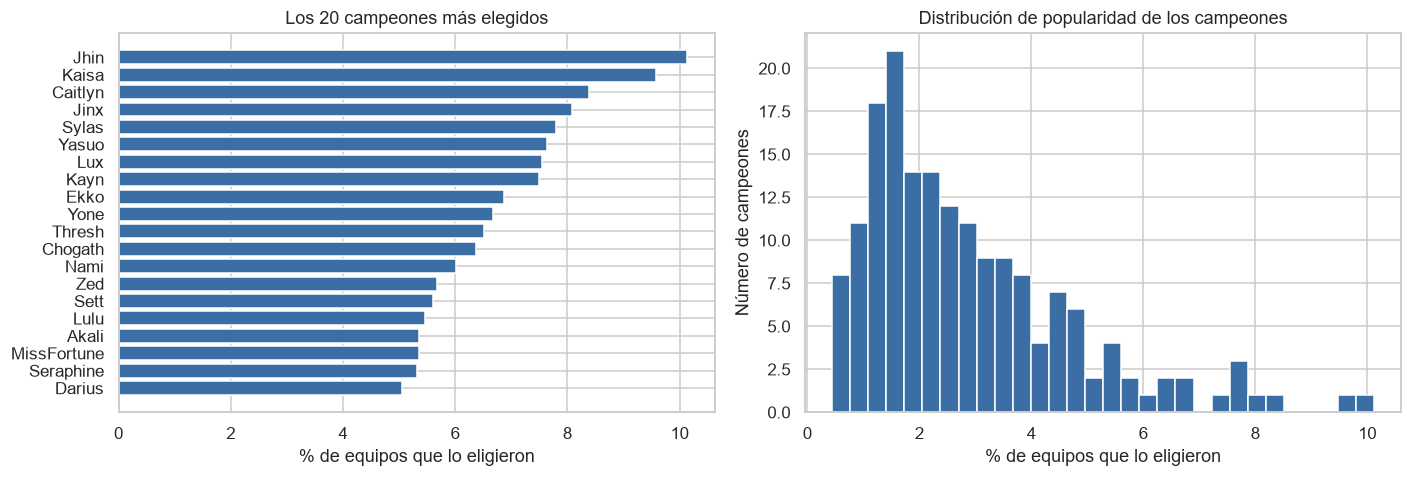

In [4]:
fig, ejes = plt.subplots(1, 2, figsize=(13, 4.5))
top = (frecuencia.head(20) / N * 100).sort_values()
ejes[0].barh(top.index, top.values, color="#3b6ea5")
ejes[0].set_xlabel("% de equipos que lo eligieron")
ejes[0].set_title("Los 20 campeones más elegidos")

ejes[1].hist(frecuencia.values / N * 100, bins=30, color="#3b6ea5")
ejes[1].set_xlabel("% de equipos que lo eligieron")
ejes[1].set_ylabel("Número de campeones")
ejes[1].set_title("Distribución de popularidad de los campeones")
plt.tight_layout()
plt.show()

**Por qué el soporte va a ser bajo.** En un supermercado un artículo como el pan puede estar en el 30 % de los
tickets. Aquí hay más de 170 campeones y cada equipo solo lleva 5, así que ni el campeón más popular pasa de
alrededor del 10 %. Un par formado por dos campeones populares e independientes tendría un soporte cercano a
0.10 × 0.10 = 1 %, y casi todos los pares quedan muy por debajo. Por eso se trabaja con soportes mínimos de
0.1 % a 0.5 % (de 85 a 425 equipos) y se usa el **lift** como criterio principal: mide cuánto más frecuente es
la combinación de lo esperado si los campeones se eligieran por separado.

## 3. De partidas a transacciones

Los algoritmos necesitan una matriz *one-hot*: una fila por transacción, una columna por artículo y `True` si
el artículo está en la transacción.

In [5]:
def one_hot(transacciones) -> pd.DataFrame:
    """Convierte una lista de transacciones en una matriz booleana."""
    codificador = TransactionEncoder()
    matriz = codificador.fit(transacciones).transform(transacciones)
    return pd.DataFrame(matriz, columns=codificador.columns_)


def texto(conjunto) -> str:
    return " + ".join(sorted(conjunto))


def sacar_reglas(itemsets: pd.DataFrame, n: int, metrica: str = "lift", umbral: float = 1.0) -> pd.DataFrame:
    """Genera reglas y deja solo las columnas que se usan, con nombres en español."""
    r = association_rules(itemsets, num_itemsets=n, metric=metrica, min_threshold=umbral)
    return pd.DataFrame({
        "antecedente": r["antecedents"],
        "consecuente": r["consequents"],
        "regla": r["antecedents"].map(texto) + "  →  " + r["consequents"].map(texto),
        "equipos": (r["support"] * n).round().astype(int),
        "soporte": r["support"],
        "confianza": r["confidence"],
        "lift": r["lift"],
    })


VISTA = ["regla", "equipos", "soporte", "confianza", "lift"]

canastas = one_hot(equipos["campeones"].tolist())
print(f"Matriz: {canastas.shape[0]:,} transacciones × {canastas.shape[1]} campeones")
print(f"Artículos por transacción: {canastas.sum(axis=1).unique()}")
canastas.iloc[:3, :8]

Matriz: 84,996 transacciones × 173 campeones
Artículos por transacción: [5]


,Aatrox,Ahri,Akali,Akshan,Alistar,Ambessa,Amumu,Anivia
0,False,False,False,False,False,False,False,False
1,False,True,False,False,True,False,False,False
2,False,False,False,False,False,False,False,False


## 4. Apriori contra FP-Growth

Los dos algoritmos encuentran exactamente los mismos conjuntos frecuentes; cambia cómo los buscan.

- **Apriori** genera candidatos por niveles (pares, luego tríos…) y recorre los datos para contar cada nivel.
- **FP-Growth** comprime las transacciones en un árbol (FP-tree) y extrae los patrones sin generar candidatos.

Se comparan con varios soportes mínimos, limitando a conjuntos de hasta 3 campeones.

In [6]:
SOPORTES = [0.01, 0.005, 0.002, 0.001]
medidas = []
for soporte in SOPORTES:
    inicio = time.perf_counter()
    con_apriori = apriori(canastas, min_support=soporte, use_colnames=True, max_len=3)
    t_apriori = time.perf_counter() - inicio

    inicio = time.perf_counter()
    con_fpgrowth = fpgrowth(canastas, min_support=soporte, use_colnames=True, max_len=3)
    t_fpgrowth = time.perf_counter() - inicio

    assert set(con_apriori["itemsets"]) == set(con_fpgrowth["itemsets"]), "Los algoritmos no coinciden"
    tamanos = con_fpgrowth["itemsets"].map(len).value_counts()
    medidas.append({
        "soporte mínimo": soporte,
        "equipos mínimos": int(np.ceil(soporte * N)),
        "individuales": int(tamanos.get(1, 0)),
        "pares": int(tamanos.get(2, 0)),
        "tríos": int(tamanos.get(3, 0)),
        "Apriori (s)": round(t_apriori, 2),
        "FP-Growth (s)": round(t_fpgrowth, 2),
    })

comparacion = pd.DataFrame(medidas)
comparacion

,soporte mínimo,equipos mínimos,individuales,pares,tríos,Apriori (s),FP-Growth (s)
0,0.0100,850,157,0,0,1.1600,1.0000
1,0.0050,425,171,53,0,1.3500,0.8900
2,0.0020,170,173,888,0,1.8500,1.1000
3,0.0010,85,173,3088,0,5.5000,1.3500


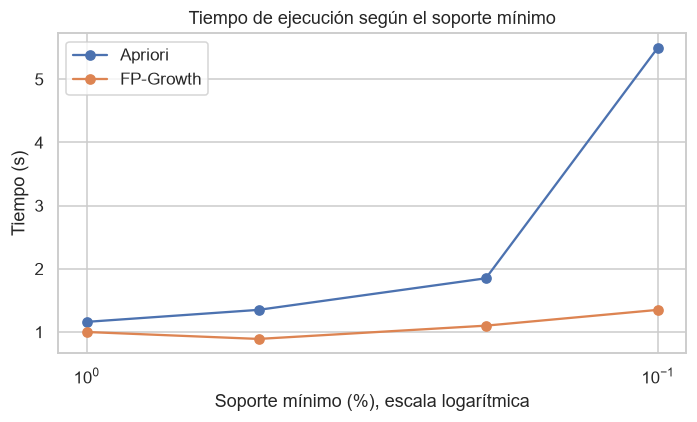

In [7]:
fig, eje = plt.subplots(figsize=(6.5, 4))
eje.plot(comparacion["soporte mínimo"] * 100, comparacion["Apriori (s)"], marker="o", label="Apriori")
eje.plot(comparacion["soporte mínimo"] * 100, comparacion["FP-Growth (s)"], marker="o", label="FP-Growth")
eje.set_xscale("log")
eje.invert_xaxis()
eje.set_xlabel("Soporte mínimo (%), escala logarítmica")
eje.set_ylabel("Tiempo (s)")
eje.set_title("Tiempo de ejecución según el soporte mínimo")
eje.legend()
plt.tight_layout()
plt.show()

Ambos algoritmos devuelven los mismos conjuntos (la celda lo comprueba con un `assert`). Con soporte de 1 % no
aparece ningún par, lo que confirma lo dicho en la exploración, y **ningún trío** llega siquiera a 0.1 %. De
aquí en adelante se usa **soporte mínimo de 0.1 %** (al menos 85 equipos) para los pares; los tríos se buscan
aparte con un soporte más bajo. Los tiempos dependen de la computadora; lo que importa es cómo cambian al
bajar el soporte: Apriori se encarece porque genera más candidatos y FP-Growth casi no cambia.

## 5. Análisis A: campeones que se eligen juntos

Métricas de cada regla *A → B*:

- **soporte**: proporción de equipos que llevan A y B.
- **confianza**: de los equipos que llevan A, qué proporción también lleva B.
- **lift**: confianza dividida entre la popularidad de B. Si es mayor a 1, B aparece con A más de lo esperado.

In [8]:
SOPORTE = 0.001
frecuentes = fpgrowth(canastas, min_support=SOPORTE, use_colnames=True, max_len=3)
reglas = sacar_reglas(frecuentes, N, metrica="lift", umbral=1.2)
print(f"Conjuntos frecuentes: {len(frecuentes):,}   Reglas con lift ≥ 1.2: {len(reglas):,}")

print("Reglas con mayor lift:")
display(reglas.sort_values("lift", ascending=False)[VISTA].head(20).reset_index(drop=True))

Conjuntos frecuentes: 3,261   Reglas con lift ≥ 1.2: 306
Reglas con mayor lift:


,regla,equipos,soporte,confianza,lift
0,Renata → Kalista,154,0.0018,0.1369,10.4537
1,Kalista → Renata,154,0.0018,0.1384,10.4537
2,Xayah → Rakan,536,0.0063,0.1654,7.5009
3,Rakan → Xayah,536,0.0063,0.2860,7.5009
4,Yuumi → Zeri,154,0.0018,0.1144,7.0367
5,Zeri → Yuumi,154,0.0018,0.1114,7.0367
6,KogMaw → Lulu,254,0.0030,0.1845,3.3731
7,Lulu → KogMaw,254,0.0030,0.0546,3.3731
8,Lulu → Yunara,628,0.0074,0.1351,3.1567
9,Yunara → Lulu,628,0.0074,0.1726,3.1567


Cada par aparece dos veces (A → B y B → A) con el mismo lift y distinta confianza. La confianza dice en qué
dirección la regla es más útil: suele ser alta cuando el antecedente es el campeón menos popular del par.

In [9]:
print("Reglas con mayor confianza (mínimo 150 equipos):")
display(reglas[reglas["equipos"] >= 150].sort_values("confianza", ascending=False)[VISTA]
        .head(15).reset_index(drop=True))

Reglas con mayor confianza (mínimo 150 equipos):


,regla,equipos,soporte,confianza,lift
0,Rakan → Xayah,536,0.0063,0.2860,7.5009
1,KogMaw → Lulu,254,0.0030,0.1845,3.3731
2,Lucian → Nami,566,0.0067,0.1825,3.0336
3,Yunara → Lulu,628,0.0074,0.1726,3.1567
4,Xayah → Rakan,536,0.0063,0.1654,7.5009
5,Lulu → Jinx,716,0.0084,0.1540,1.9053
6,Ashe → Seraphine,596,0.0070,0.1511,2.8423
7,Nautilus → Kaisa,547,0.0064,0.1452,1.5159
8,Zyra → Jhin,252,0.0030,0.1447,1.4295
9,Zilean → Jhin,179,0.0021,0.1442,1.4246


**Tríos.** Con 0.1 % no hay ningún conjunto de tres campeones. Para verlos se baja el soporte a 0.03 % (unos 26
equipos). Con tan pocos casos estas reglas son solo exploratorias: se muestran las de la forma *par → campeón*.

In [10]:
frecuentes_trios = fpgrowth(canastas, min_support=0.0003, use_colnames=True, max_len=3)
reglas_trios = sacar_reglas(frecuentes_trios, N, metrica="lift", umbral=1.5)
trios = reglas_trios[(reglas_trios["antecedente"].map(len) == 2) & (reglas_trios["consecuente"].map(len) == 1)]
print(f"Tríos frecuentes con soporte ≥ 0.03 %: {(frecuentes_trios['itemsets'].map(len) == 3).sum()}")
display(trios.sort_values("lift", ascending=False)[VISTA].head(12).reset_index(drop=True))

Tríos frecuentes con soporte ≥ 0.03 %: 473


,regla,equipos,soporte,confianza,lift
0,Diana + Xayah → Rakan,26,0.0003,0.2222,10.0790
1,MonkeyKing + Rakan → Xayah,29,0.0003,0.3766,9.8770
2,Akali + Rakan → Xayah,34,0.0004,0.3400,8.9166
3,Chogath + Rakan → Xayah,40,0.0005,0.3361,8.8152
4,LeeSin + Xayah → Rakan,29,0.0003,0.1933,8.7687
5,Rakan + Sylas → Xayah,46,0.0005,0.3262,8.5558
6,MonkeyKing + Xayah → Rakan,29,0.0003,0.1859,8.4315
7,Chogath + Xayah → Rakan,40,0.0005,0.1852,8.3991
8,Ahri + Rakan → Xayah,29,0.0003,0.3187,8.3575
9,Diana + Rakan → Xayah,26,0.0003,0.3133,8.2151


Casi todos los tríos son el par Xayah + Rakan más un tercer campeón popular, con un lift parecido al del par
solo (7.5). Son reglas **redundantes**: el tercer campeón no agrega información.

## 6. Análisis B: campeón + rol

En el análisis anterior, `Lulu` es el mismo artículo sin importar la posición. Aquí cada artículo es
*campeón_rol* (por ejemplo `Lulu_SUP`), lo que permite ver entre qué posiciones ocurre la asociación.

In [11]:
canastas_rol = one_hot(equipos["con_rol"].tolist())
frecuentes_rol = fpgrowth(canastas_rol, min_support=SOPORTE, use_colnames=True, max_len=2)
reglas_rol = sacar_reglas(frecuentes_rol, N, metrica="lift", umbral=1.2)


def roles_de(fila) -> str:
    roles = sorted(a.split("_")[-1] for a in fila["antecedente"] | fila["consecuente"])
    return "-".join(roles)


reglas_rol["roles"] = reglas_rol.apply(roles_de, axis=1)
pares_rol = reglas_rol[reglas_rol["antecedente"].map(texto) < reglas_rol["consecuente"].map(texto)]
print(f"Artículos campeón_rol: {canastas_rol.shape[1]}   Pares con lift ≥ 1.2: {len(pares_rol)}")

print("¿Entre qué roles hay más asociaciones?")
display(pares_rol.groupby("roles").agg(pares=("lift", "size"), lift_promedio=("lift", "mean"),
                                       lift_maximo=("lift", "max")).sort_values("pares", ascending=False))

Artículos campeón_rol: 831   Pares con lift ≥ 1.2: 224
¿Entre qué roles hay más asociaciones?


,pares,lift_promedio,lift_maximo
roles,,,
ADC-SUP,72,1.9973,11.0935
JG-MID,34,1.4709,3.0413
MID-SUP,26,1.2875,1.3916
MID-TOP,22,1.3379,1.5262
JG-TOP,17,1.2840,1.6359
ADC-MID,13,1.3292,2.1914
SUP-TOP,13,1.2686,1.3452
JG-SUP,11,1.2574,1.3342
ADC-TOP,10,1.2662,1.4024


In [12]:
print("Mejores pares fuera de la línea inferior (ADC-SUP):")
display(pares_rol[pares_rol["roles"] != "ADC-SUP"].sort_values("lift", ascending=False)[VISTA + ["roles"]]
        .head(15).reset_index(drop=True))

Mejores pares fuera de la línea inferior (ADC-SUP):


,regla,equipos,soporte,confianza,lift,roles
0,Diana_JG → Yasuo_MID,253,0.0030,0.1570,3.0413,JG-MID
1,Yasuo_MID → Ziggs_ADC,86,0.0010,0.0196,2.1914,ADC-MID
2,Lillia_JG → Zed_MID,192,0.0023,0.0850,1.9611,JG-MID
3,Diana_JG → Yone_MID,115,0.0014,0.0714,1.8796,JG-MID
4,Evelynn_JG → Zed_MID,85,0.0010,0.0759,1.7519,JG-MID
5,FiddleSticks_JG → Yone_MID,100,0.0012,0.0637,1.6761,JG-MID
6,Aatrox_TOP → Lillia_JG,92,0.0011,0.0435,1.6359,JG-TOP
7,Ekko_JG → Yone_MID,157,0.0018,0.0619,1.6301,JG-MID
8,Lillia_JG → Yone_MID,138,0.0016,0.0611,1.6078,JG-MID
9,Diana_JG → Zed_MID,112,0.0013,0.0695,1.6049,JG-MID


## 7. Análisis C: combinaciones asociadas con la victoria

Se agrega el resultado como un artículo más (`VICTORIA` o `DERROTA`) y se buscan reglas cuyo consecuente sea
el resultado. En estas reglas la **confianza es la tasa de victoria** de la combinación, y como exactamente la
mitad de los equipos gana, `lift = confianza / 0.5`.

Con pocos equipos una tasa de victoria alta puede ser casualidad. Por eso se agrega el **valor z**: cuántas
desviaciones estándar se aleja la tasa de victoria del 50 % dado el número de equipos. Como referencia,
|z| > 2 es poco probable por azar en una sola prueba; al revisar miles de combinaciones a la vez, conviene
exigir más (|z| > 3).

In [13]:
con_resultado = [c + ["VICTORIA" if g else "DERROTA"] for c, g in zip(equipos["campeones"], equipos["gana"])]
canastas_res = one_hot(con_resultado)
# soporte a la mitad: un par con 150 equipos reparte sus casos entre VICTORIA y DERROTA
frecuentes_res = fpgrowth(canastas_res, min_support=SOPORTE / 2, use_colnames=True, max_len=3)
reglas_res = sacar_reglas(frecuentes_res, N, metrica="confidence", umbral=0.0)

RESULTADOS = {"VICTORIA", "DERROTA"}
hacia_resultado = reglas_res[
    reglas_res["consecuente"].map(lambda c: len(c) == 1 and next(iter(c)) in RESULTADOS)
    & reglas_res["antecedente"].map(lambda a: not (a & RESULTADOS))
].copy()
hacia_resultado["equipos_antecedente"] = (hacia_resultado["equipos"] / hacia_resultado["confianza"]).round().astype(int)
hacia_resultado["z"] = (hacia_resultado["confianza"] - 0.5) / np.sqrt(0.25 / hacia_resultado["equipos_antecedente"])
hacia_resultado["tamaño"] = hacia_resultado["antecedente"].map(len)

victoria = hacia_resultado[hacia_resultado["consecuente"] == frozenset({"VICTORIA"})]
COLUMNAS = ["regla", "equipos_antecedente", "confianza", "lift", "z"]

print("Campeones individuales con mayor tasa de victoria (mínimo 500 equipos):")
display(victoria[(victoria["tamaño"] == 1) & (victoria["equipos_antecedente"] >= 500)]
        .sort_values("confianza", ascending=False)[COLUMNAS].head(10).reset_index(drop=True))

print("Pares más asociados con ganar (mínimo 150 equipos):")
display(victoria[(victoria["tamaño"] >= 2) & (victoria["equipos_antecedente"] >= 150)]
        .sort_values("z", ascending=False)[COLUMNAS].head(15).reset_index(drop=True))

print("Pares más asociados con perder (mínimo 150 equipos):")
display(victoria[(victoria["tamaño"] >= 2) & (victoria["equipos_antecedente"] >= 150)]
        .sort_values("z")[COLUMNAS].head(10).reset_index(drop=True))

Campeones individuales con mayor tasa de victoria (mínimo 500 equipos):


,regla,equipos_antecedente,confianza,lift,z
0,Rammus → VICTORIA,1045,0.5675,1.1349,4.3618
1,Braum → VICTORIA,2268,0.5401,1.0802,3.8216
2,MonkeyKing → VICTORIA,3980,0.5379,1.0759,4.7870
3,Zyra → VICTORIA,1741,0.5370,1.0741,3.0917
4,Lillia → VICTORIA,2303,0.5363,1.0725,3.4799
5,Fizz → VICTORIA,2823,0.5349,1.0698,3.7078
6,KogMaw → VICTORIA,1377,0.5330,1.0661,2.4523
7,Malphite → VICTORIA,3980,0.5274,1.0548,3.4555
8,MasterYi → VICTORIA,2924,0.5274,1.0547,2.9589
9,Sejuani → VICTORIA,1218,0.5271,1.0542,1.8911


Pares más asociados con ganar (mínimo 150 equipos):


,regla,equipos_antecedente,confianza,lift,z
0,Braum + Jinx → VICTORIA,242,0.6116,1.2231,3.4713
1,Ekko + Thresh → VICTORIA,405,0.5827,1.1654,3.3293
2,Jhin + Senna → VICTORIA,322,0.5870,1.1739,3.1208
3,Darius + Senna → VICTORIA,153,0.6209,1.2418,2.9913
4,Malphite + MonkeyKing → VICTORIA,162,0.6173,1.2346,2.9856
5,Jhin + MonkeyKing → VICTORIA,377,0.5756,1.1512,2.9356
6,Jhin + Xerath → VICTORIA,305,0.5836,1.1672,2.9203
7,Lulu + MonkeyKing → VICTORIA,228,0.5965,1.1930,2.9140
8,Nami + Warwick → VICTORIA,156,0.6154,1.2308,2.8823
9,Fizz + Sett → VICTORIA,176,0.6080,1.2159,2.8644


Pares más asociados con perder (mínimo 150 equipos):


,regla,equipos_antecedente,confianza,lift,z
0,Ezreal + LeeSin → VICTORIA,200,0.3400,0.6800,-4.5255
1,Karma + Zed → VICTORIA,170,0.3824,0.7647,-3.0679
2,Ezreal + Karma → VICTORIA,333,0.4174,0.8348,-3.0140
3,Ezreal + Qiyana → VICTORIA,169,0.3846,0.7692,-3.0000
4,Lucian + Sylas → VICTORIA,249,0.4056,0.8112,-2.9785
5,Akali + Viego → VICTORIA,228,0.4035,0.8070,-2.9140
6,LeeSin + Sylas → VICTORIA,198,0.3990,0.7980,-2.8427
7,LeeSin + Sett → VICTORIA,203,0.4039,0.8079,-2.7373
8,Caitlyn + Galio → VICTORIA,182,0.4011,0.8022,-2.6685
9,Ekko + Smolder → VICTORIA,219,0.4110,0.8219,-2.6354


**¿Cuánto de esto es casualidad?** Si ningún par influyera en el resultado, por puro azar el 4.6 % de los pares
tendría |z| > 2 y el 0.27 % tendría |z| > 3. La siguiente celda compara esos porcentajes con los observados.

In [14]:
for nombre, tam, minimo in (("Campeones individuales", 1, 500), ("Pares", 2, 150)):
    grupo = victoria[(victoria["tamaño"] == tam) & (victoria["equipos_antecedente"] >= minimo)]
    print(f"{nombre} (mínimo {minimo} equipos): {len(grupo)} evaluados")
    print(f"   |z| > 2: {(grupo['z'].abs() > 2).mean():.1%} observado contra 4.6 % esperado por azar")
    print(f"   |z| > 3: {(grupo['z'].abs() > 3).mean():.2%} observado contra 0.27 % esperado por azar")

Campeones individuales (mínimo 500 equipos): 168 evaluados
   |z| > 2: 22.0% observado contra 4.6 % esperado por azar
   |z| > 3: 10.71% observado contra 0.27 % esperado por azar
Pares (mínimo 150 equipos): 1175 evaluados
   |z| > 2: 7.5% observado contra 4.6 % esperado por azar
   |z| > 3: 0.51% observado contra 0.27 % esperado por azar


**¿La combinación aporta algo o solo son dos campeones fuertes?** Un par puede ganar mucho simplemente porque
sus dos campeones ganan mucho por separado. Para separar eso, se compara la tasa de victoria del par contra la
de sus campeones individuales: la **ganancia** es la tasa del par menos la mayor de las dos individuales.

In [15]:
tasa_individual = (victoria[victoria["tamaño"] == 1]
                   .assign(campeon=lambda d: d["antecedente"].map(lambda a: next(iter(a))))
                   .set_index("campeon")["confianza"])

pares_v = victoria[(victoria["tamaño"] == 2) & (victoria["equipos_antecedente"] >= 150)].copy()
pares_v["mejor_individual"] = pares_v["antecedente"].map(lambda a: max(tasa_individual.get(c, np.nan) for c in a))
pares_v["ganancia"] = pares_v["confianza"] - pares_v["mejor_individual"]
pares_v["par"] = pares_v["antecedente"].map(texto)

print("Pares que ganan más que cualquiera de sus campeones por separado:")
display(pares_v.sort_values("ganancia", ascending=False)
        [["par", "equipos_antecedente", "confianza", "mejor_individual", "ganancia", "z"]]
        .head(12).reset_index(drop=True))

Pares que ganan más que cualquiera de sus campeones por separado:


,par,equipos_antecedente,confianza,mejor_individual,ganancia,z
0,Garen + Seraphine,172,0.5988,0.4984,0.1005,2.5925
1,Darius + Senna,153,0.6209,0.5266,0.0943,2.9913
2,Nami + Warwick,156,0.6154,0.5235,0.0919,2.8823
3,Galio + Jhin,244,0.5902,0.5008,0.0894,2.8168
4,MasterYi + Veigar,162,0.6111,0.5274,0.0838,2.8284
5,Ornn + Yasuo,177,0.5932,0.5123,0.0809,2.4804
6,Malphite + MonkeyKing,162,0.6173,0.5379,0.0793,2.9856
7,Yuumi + Zeri,154,0.5649,0.4877,0.0772,1.6116
8,Malphite + Tristana,169,0.6036,0.5274,0.0762,2.6923
9,MissFortune + Pyke,153,0.5752,0.5002,0.0749,1.8594


## 8. Análisis D: asociaciones contra el equipo rival

Ahora cada transacción lleva los 5 campeones propios y los 5 del rival con el prefijo `vs_`. Las reglas
`vs_X → Y` dicen: *cuando el rival lleva X, mi equipo lleva Y más de lo esperado*.

Los datos no guardan el orden en que se eligió cada campeón, así que la regla no prueba que Y sea una
*respuesta* a X: también puede ser que X se elija contra Y. Es una asociación entre equipos, sin dirección.

In [16]:
con_rival = [c + [f"vs_{r}" for r in rv] for c, rv in zip(equipos["campeones"], equipos["rivales"])]
canastas_rival = one_hot(con_rival)
frecuentes_rival = fpgrowth(canastas_rival, min_support=SOPORTE, use_colnames=True, max_len=2)
reglas_rival = sacar_reglas(frecuentes_rival, N, metrica="lift", umbral=1.0)


def es_rival(conjunto) -> bool:
    return all(a.startswith("vs_") for a in conjunto)


cruzadas = reglas_rival[reglas_rival["antecedente"].map(es_rival) & ~reglas_rival["consecuente"].map(es_rival)]
print(f"Reglas rival → propio con lift ≥ 1: {len(cruzadas):,}")
display(cruzadas[cruzadas["equipos"] >= 150].sort_values("lift", ascending=False)[VISTA]
        .head(15).reset_index(drop=True))

Reglas rival → propio con lift ≥ 1: 4,722


,regla,equipos,soporte,confianza,lift
0,vs_Garen → Jax,197,0.0023,0.0582,1.7502
1,vs_Jax → Garen,197,0.0023,0.0697,1.7502
2,vs_Sylas → Malphite,538,0.0063,0.0811,1.7322
3,vs_Malphite → Sylas,538,0.0063,0.1352,1.7322
4,vs_Thresh → Braum,237,0.0028,0.0428,1.6038
5,vs_Braum → Thresh,237,0.0028,0.1045,1.6038
6,vs_Galio → Akali,209,0.0025,0.0843,1.5760
7,vs_Akali → Galio,209,0.0025,0.0460,1.5760
8,vs_Nautilus → Braum,154,0.0018,0.0409,1.5325
9,vs_Braum → Nautilus,154,0.0018,0.0679,1.5325


## 9. Comparación por rango

¿Las mismas asociaciones aparecen en Platino, Esmeralda y Diamante? Para cada rango se calcula directamente el
lift de los pares más fuertes del análisis A.

In [17]:
def lift_de_pares(matriz: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Devuelve (conteos, lift) de todos los pares de columnas de una matriz one-hot."""
    x = matriz.to_numpy(dtype=np.int32)
    n = len(x)
    juntos = x.T @ x
    individual = np.diag(juntos)
    with np.errstate(divide="ignore", invalid="ignore"):
        lift = juntos * n / np.outer(individual, individual)
    return (pd.DataFrame(juntos, index=matriz.columns, columns=matriz.columns),
            pd.DataFrame(lift, index=matriz.columns, columns=matriz.columns))


pares_top = (reglas[(reglas["antecedente"].map(len) == 1) & (reglas["consecuente"].map(len) == 1)
                    & (reglas["equipos"] >= 200)]
             .assign(par=lambda d: d.apply(lambda f: frozenset(f["antecedente"] | f["consecuente"]), axis=1))
             .drop_duplicates("par").sort_values("lift", ascending=False).head(12))

tabla = pd.DataFrame({"par": pares_top["par"].map(texto).values, "Global": pares_top["lift"].round(2).values})
for rango in ["Platino", "Esmeralda", "Diamante"]:
    conteos_r, lift_r = lift_de_pares(canastas[(equipos["rango"] == rango).values])
    tabla[rango] = [round(lift_r.loc[tuple(sorted(p))], 2) for p in pares_top["par"]]
    tabla[f"n {rango}"] = [int(conteos_r.loc[tuple(sorted(p))]) for p in pares_top["par"]]
tabla

,par,Global,Platino,n Platino,Esmeralda,n Esmeralda,Diamante,n Diamante
0,Rakan + Xayah,7.5000,8.5300,165,7.1900,118,7.0000,253
1,KogMaw + Lulu,3.3700,3.1900,53,3.6300,75,3.2800,126
2,Lulu + Yunara,3.1600,2.6600,108,3.2600,168,3.1700,352
3,Lucian + Nami,3.0300,3.0500,108,2.7600,133,2.9900,325
4,Ashe + Seraphine,2.8400,2.3100,187,2.8000,156,3.4200,253
5,Nautilus + Samira,2.8400,2.7200,74,2.6100,57,3.1000,100
6,Leona + Samira,2.7300,2.4500,66,2.5600,54,3.1300,91
7,Lucian + Milio,2.5300,1.6700,46,2.6000,91,2.6700,214
8,Braum + Lucian,2.5000,2.9300,48,2.4200,54,2.2800,105
9,Ezreal + Karma,2.2400,2.3300,82,2.2400,89,2.1900,162


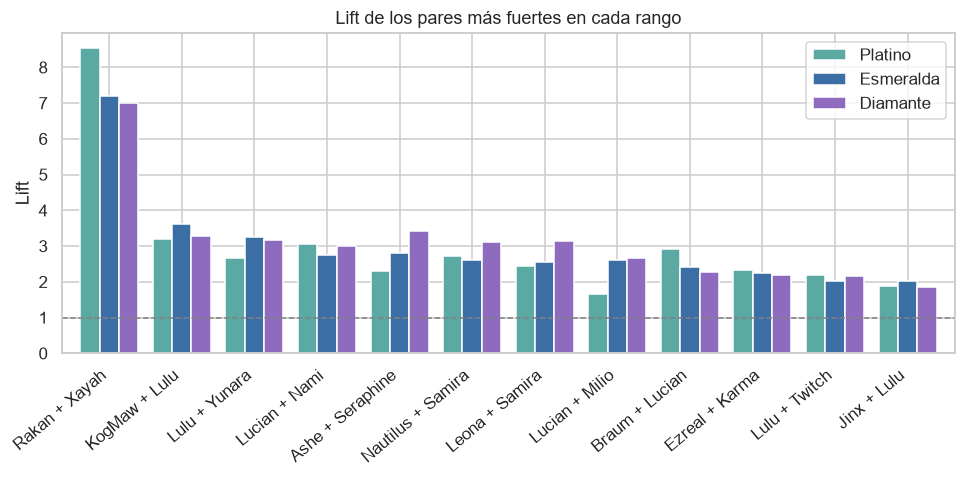

In [18]:
fig, eje = plt.subplots(figsize=(9, 4.5))
tabla.set_index("par")[["Platino", "Esmeralda", "Diamante"]].plot.bar(ax=eje, width=0.8,
                                                                    color=["#5aa9a3", "#3b6ea5", "#8e6bbf"])
eje.axhline(1, color="gray", linestyle="--", linewidth=1)
eje.set_ylabel("Lift")
eje.set_xlabel("")
eje.set_title("Lift de los pares más fuertes en cada rango")
plt.xticks(rotation=40, ha="right")
plt.tight_layout()
plt.show()

## 10. Visualizaciones

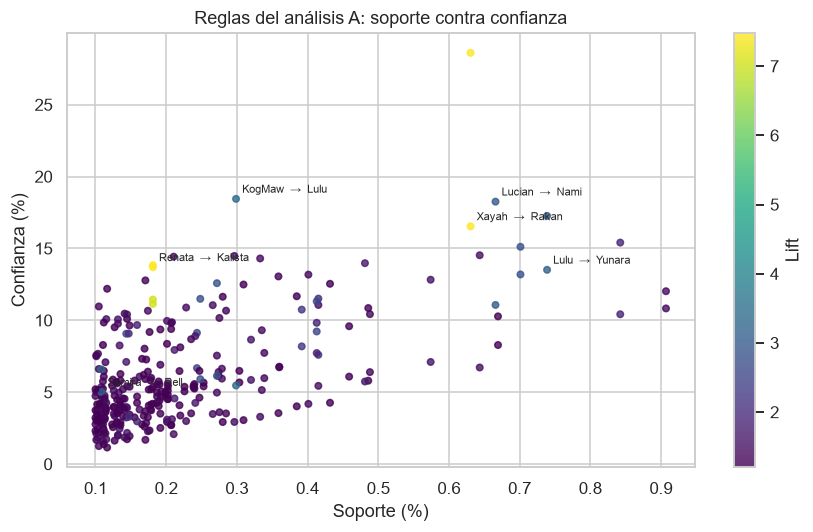

In [19]:
fig, eje = plt.subplots(figsize=(8, 5))
puntos = eje.scatter(reglas["soporte"] * 100, reglas["confianza"] * 100, c=reglas["lift"],
                     cmap="viridis", s=18, alpha=0.8, vmax=reglas["lift"].quantile(0.99))
fig.colorbar(puntos, label="Lift")
for _, fila in reglas.sort_values("lift", ascending=False).drop_duplicates("soporte").head(6).iterrows():
    eje.annotate(fila["regla"], (fila["soporte"] * 100, fila["confianza"] * 100), fontsize=7,
                 xytext=(4, 4), textcoords="offset points")
eje.set_xlabel("Soporte (%)")
eje.set_ylabel("Confianza (%)")
eje.set_title("Reglas del análisis A: soporte contra confianza")
plt.tight_layout()
plt.show()

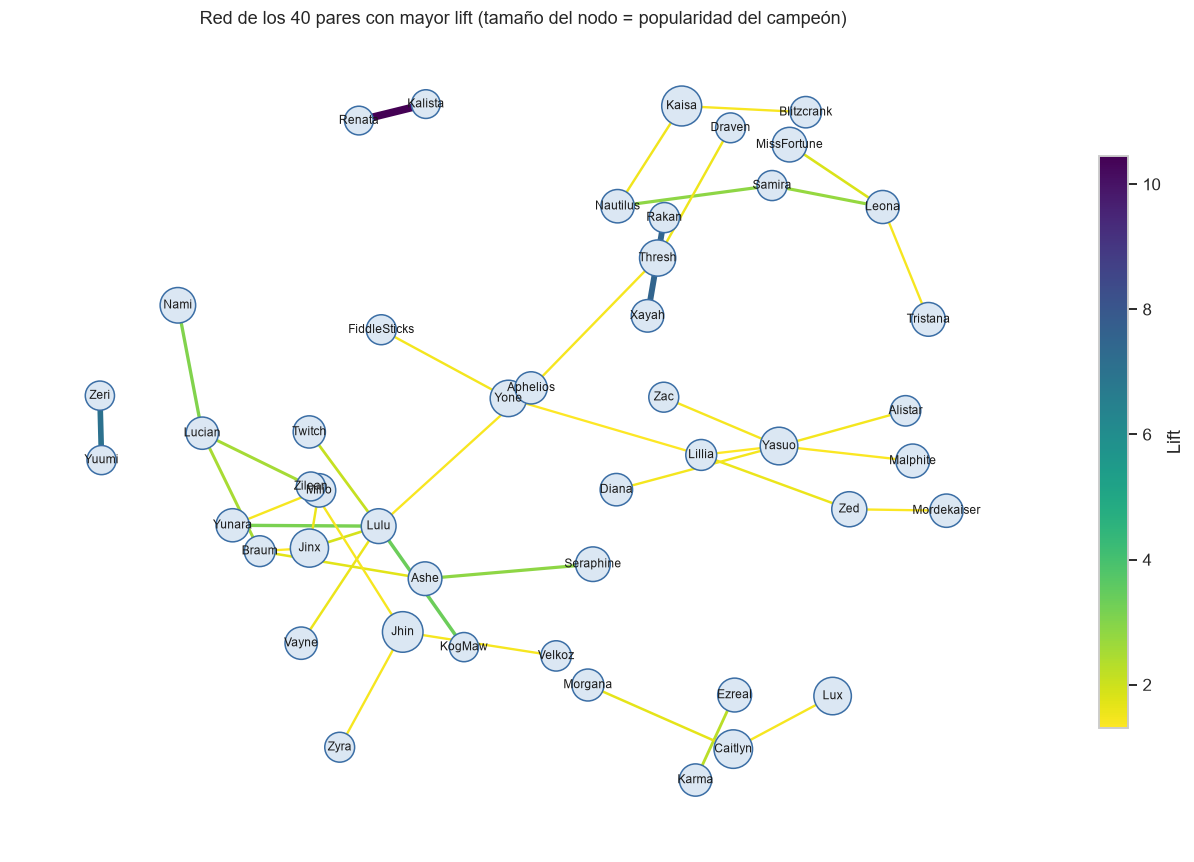

In [20]:
pares_grafo = (reglas[(reglas["antecedente"].map(len) == 1) & (reglas["consecuente"].map(len) == 1)
                      & (reglas["equipos"] >= 150)]
               .assign(par=lambda d: d.apply(lambda f: frozenset(f["antecedente"] | f["consecuente"]), axis=1))
               .drop_duplicates("par").sort_values("lift", ascending=False).head(40))

grafo = nx.Graph()
for _, fila in pares_grafo.iterrows():
    a, b = sorted(fila["par"])
    grafo.add_edge(a, b, lift=fila["lift"])

posicion = nx.spring_layout(grafo, k=1.4, iterations=200, seed=3)
lifts = np.array([d["lift"] for _, _, d in grafo.edges(data=True)])
tamano = [300 + 4000 * frecuencia[n] / N for n in grafo.nodes]

fig, eje = plt.subplots(figsize=(12, 8))
nx.draw_networkx_nodes(grafo, posicion, node_size=tamano, node_color="#dbe7f3", edgecolors="#3b6ea5", ax=eje)
aristas = nx.draw_networkx_edges(grafo, posicion, width=1 + lifts / lifts.max() * 4, edge_color=lifts,
                                 edge_cmap=plt.cm.viridis_r, ax=eje)
nx.draw_networkx_labels(grafo, posicion, font_size=8, ax=eje)
fig.colorbar(aristas, ax=eje, label="Lift", shrink=0.7)
eje.set_title("Red de los 40 pares con mayor lift (tamaño del nodo = popularidad del campeón)")
eje.axis("off")
plt.tight_layout()
plt.show()

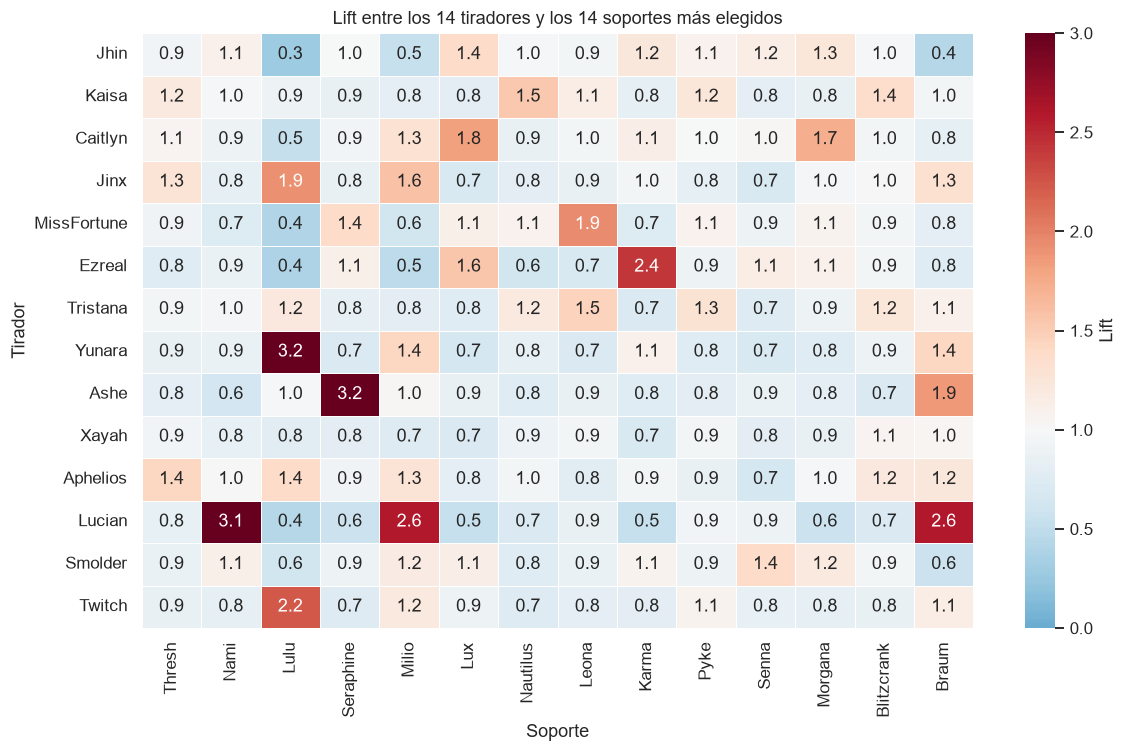

In [21]:
conteos_rol, lift_rol = lift_de_pares(canastas_rol)
populares = canastas_rol.sum().sort_values(ascending=False)
tiradores = [c for c in populares.index if c.endswith("_ADC")][:14]
soportes = [c for c in populares.index if c.endswith("_SUP")][:14]

mapa = lift_rol.loc[tiradores, soportes]
mapa.index = [c.replace("_ADC", "") for c in mapa.index]
mapa.columns = [c.replace("_SUP", "") for c in mapa.columns]

fig, eje = plt.subplots(figsize=(11, 7))
sns.heatmap(mapa, annot=True, fmt=".1f", cmap="RdBu_r", center=1, vmin=0, vmax=3, linewidths=0.5,
            cbar_kws={"label": "Lift"}, ax=eje)
eje.set_xlabel("Soporte")
eje.set_ylabel("Tirador")
eje.set_title("Lift entre los 14 tiradores y los 14 soportes más elegidos")
plt.tight_layout()
plt.show()

En el mapa, el rojo marca parejas que se eligen juntas más de lo esperado (lift > 1) y el azul parejas que se
evitan (lift < 1). Las asociaciones negativas no las entregan Apriori ni FP-Growth, porque solo guardan
combinaciones frecuentes; aquí se ven porque el lift se calculó directamente para todos los pares.

## 11. Mini recomendador basado en reglas

Con las reglas del análisis A se puede sugerir un campeón: se buscan las reglas cuyo antecedente ya está
completo en el equipo y cuyo consecuente todavía no se ha elegido, y se ordenan por lift.

In [22]:
def recomendar(picks: list[str], cuantos: int = 3, minimo_equipos: int = 100) -> pd.DataFrame:
    """Sugiere campeones para un equipo a partir de las reglas de asociación."""
    actuales = frozenset(picks)
    candidatas = reglas[
        reglas["antecedente"].map(lambda a: a <= actuales)
        & reglas["consecuente"].map(lambda c: len(c) == 1 and not (c & actuales))
        & (reglas["equipos"] >= minimo_equipos)
    ].copy()
    candidatas["sugerencia"] = candidatas["consecuente"].map(texto)
    candidatas["porque_llevas"] = candidatas["antecedente"].map(texto)
    mejores = candidatas.sort_values("lift", ascending=False).drop_duplicates("sugerencia").head(cuantos)
    return mejores[["sugerencia", "porque_llevas", "equipos", "confianza", "lift"]].reset_index(drop=True)


for ejemplo in (["Xayah"], ["Lucian"], ["Yasuo", "Jinx"]):
    print("Equipo:", ", ".join(ejemplo))
    display(recomendar(ejemplo))

Equipo: Xayah


,sugerencia,porque_llevas,equipos,confianza,lift
0,Rakan,Xayah,536,0.1654,7.5009
1,Gwen,Xayah,164,0.0506,1.2198
2,Akali,Xayah,210,0.0648,1.2112


Equipo: Lucian


,sugerencia,porque_llevas,equipos,confianza,lift
0,Nami,Lucian,566,0.1825,3.0336
1,Milio,Lucian,351,0.1132,2.5278
2,Braum,Lucian,207,0.0668,2.5016


Equipo: Yasuo, Jinx


,sugerencia,porque_llevas,equipos,confianza,lift
0,Lulu,Jinx,716,0.1042,1.9053
1,Milio,Jinx,488,0.0710,1.5859
2,Diana,Yasuo,353,0.0544,1.4495


Este recomendador sugiere lo que la gente **suele elegir** junto a esos campeones, no necesariamente lo que
más gana. Combinarlo con las tasas de victoria del análisis C queda como pendiente.

## 12. Conclusiones, limitaciones y pendientes

### Conclusiones

1. **Sí hay reglas de asociación reales en los drafts, y casi todas están en la línea inferior.** Los pares con
   mayor lift son tirador + soporte: Kalista + Renata (10.5), Xayah + Rakan (7.5), Zeri + Yuumi (7.0),
   Kog'Maw + Lulu (3.4), Yunara + Lulu (3.2) y Lucian + Nami (3.0). Al separar por rol, 72 de los 224 pares con
   lift ≥ 1.2 son ADC-SUP, con el lift promedio más alto. Coinciden con sinergias conocidas del juego, lo que
   valida el método.
2. **Fuera de la línea inferior, la asociación más clara es jungla + medio:** Diana con Yasuo (3.0) y varios
   junglas con Yasuo, Yone y Zed.
3. **El soporte es muy bajo por la naturaleza de los datos.** Ningún par llega a 1 % y ningún trío a 0.1 %. La
   confianza también es baja (la regla más confiable, Rakan → Xayah, tiene 29 %), así que estas reglas sirven
   para describir preferencias, no para predecir con certeza el siguiente campeón. El lift fue la métrica útil.
4. **Los tríos no aportan reglas nuevas.** Los que aparecen son casi todos Xayah + Rakan más un tercer campeón
   popular, con un lift parecido al del par: son reglas redundantes.
5. **Apriori y FP-Growth dan los mismos conjuntos.** FP-Growth se mantuvo casi constante al bajar el soporte y
   Apriori se volvió varias veces más lento con 0.1 %.
6. **Elegirse juntos no es lo mismo que ganar juntos.** Lucian + Nami se elige 3 veces más de lo esperado y
   gana menos de la mitad de sus partidas; Ezreal + Karma (lift 2.2) está entre los pares que más pierden.
7. **Con estos datos, el efecto de los pares sobre la victoria apenas se distingue del azar.** En campeones
   individuales, el 22 % tiene |z| > 2 (se espera 4.6 % por azar): hay campeones que claramente ganan más. En
   pares, solo el 7.5 % tiene |z| > 2 y el 0.5 % tiene |z| > 3, muy cerca de lo esperado por azar. La lista de
   "pares ganadores" debe leerse como candidatos a revisar con más partidas, no como hallazgos firmes.
8. **Las asociaciones se mantienen en los tres rangos.** Los pares más fuertes tienen lift parecido en Platino,
   Esmeralda y Diamante; las diferencias se dan en pares con pocos casos por rango.
9. **Entre equipos las asociaciones son más débiles** (lift máximo cercano a 1.75, contra 10.5 dentro del
   equipo), por ejemplo Garen contra Jax o Malphite contra Sylas.

### Limitaciones

- Una sola región (LAN), tres parches y tres rangos: las reglas describen ese meta y pueden cambiar con cada
  parche.
- Los datos no incluyen el orden de selección, así que no se puede saber qué campeón se eligió en respuesta a
  cuál.
- Jugadores que hacen fila en dúo eligen parejas a propósito; eso infla el lift de la línea inferior y no se
  puede separar con estos datos.
- Con soportes tan bajos, muchas reglas descansan en 100 a 200 equipos.
- Las asociaciones negativas (campeones que se evitan) no salen de Apriori ni de FP-Growth; solo se ven en el
  mapa de calor.

### Pendientes

La lista completa de cambios por hacer está en `PENDIENTES.md`, junto a este notebook.